# 阶段一 · 1.3 初步探查

> 对应文档《智慧审计机器学习期中流程图》表 2 的步骤 **1.3 初步探查**。

**目标：** 在清洗之前先摸清数据的"家底"，并留下可以复查的记录。

这一步要回答五个问题：

1. 数据有多大？每列是什么类型？
2. 59 个字段能按业务分成哪几组？
3. 标签怎么分布？异常比例是多少？
4. 数值字段有没有严重偏态？需不需要 log 变换？
5. 有没有重复、负金额、时间戳异常等质量问题？

**留痕方式：** 每个代码块都会打印带标题的结果；关键表格保存到 `../outputs/`，图表保存到 `../outputs/figures/`。以后回头比对，直接看这些文件即可，不用重新跑 notebook。

**阅读建议：** 先看代码上方的说明，再对照输出。想实验时改一个参数（比如直方图的 `bins`）重跑，对比差异。

## 1. 读取数据，先确认规模

文档预期：**7,000 行 × 59 列**，CSV 约 3.7 MB。先验证实际读进来是否一致——如果行列数对不上，后面的所有结论都不可信。

In [1]:
# ============================================================
# 环境与路径设置
# notebook 位于 notebooks/，数据在 ../data/，留痕文件写到 ../outputs/
# ============================================================
import sys
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# 让 matplotlib 正常显示中文和负号（Windows 自带微软雅黑）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 表格显示设置：不截断列名和内容，方便阅读
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 60)

DATA_PATH = Path('../data/audit_raw.csv')
OUT_DIR = Path('../outputs')
FIG_DIR = OUT_DIR / 'figures'
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

print('运行时间 :', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python   :', sys.version.split()[0])
print('pandas   :', pd.__version__, '| numpy:', np.__version__, '| matplotlib:', matplotlib.__version__)
print('数据文件 :', DATA_PATH.resolve())
print('留痕目录 :', OUT_DIR.resolve())

运行时间 : 2026-10-18 22:47:17
Python   : 3.13.9
pandas   : 2.3.3 | numpy: 2.3.5 | matplotlib: 3.10.6
数据文件 : D:\ProjectFiles\VscodeProject\audit_ml_project\data\audit_raw.csv
留痕目录 : D:\ProjectFiles\VscodeProject\audit_ml_project\outputs


In [2]:
# 读取原始数据。原始文件只读不改，所有修改都另存为新文件。
df = pd.read_csv(DATA_PATH)

print(f'数据规模: {df.shape[0]:,} 行 × {df.shape[1]} 列')
print(f'内存占用: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB')

# 和文档预期对比
expected = (7000, 59)
print(f'与文档预期 {expected[0]:,} 行 × {expected[1]} 列一致: {df.shape == expected}')

print('\n=== 前 5 行 ===')
display(df.head())

数据规模: 7,000 行 × 59 列
内存占用: 11.7 MB
与文档预期 7,000 行 × 59 列一致: True

=== 前 5 行 ===


,Transaction_ID,Transaction_DateTime,Fiscal_Year,Fiscal_Quarter,Month,Hour,Weekend_Flag,Night_Transaction_Flag,Source_Node_ID,Destination_Node_ID,Source_Node_Index,Destination_Node_Index,Source_Entity_ID,Destination_Entity_ID,Source_Entity_Name,Destination_Entity_Name,Source_Bank,Destination_Bank,Source_Province,Destination_Province,Source_City,Destination_City,Source_Account_Type,Destination_Account_Type,Source_Account_Age_Days,Destination_Account_Age_Days,Currency,Transaction_Amount_RMB,Historical_Avg_Amount_RMB,Transaction_to_Avg_Ratio,Approval_Threshold_RMB,Amount_Threshold_Ratio,Payment_Channel,Invoice_ID,Invoice_Type,Invoice_Match_Score,Tax_Validation_Flag,Duplicate_Invoice_Flag,Edge_Type,Same_Bank_Flag,Province_Mismatch_Flag,Related_Party_Flag,Time_Since_Last_Transaction_Min,Approval_Level,Approval_Delay_Min,Vendor_Risk_Score,Source_Account_Degree,Destination_Account_Degree,Source_PageRank,Destination_PageRank,Common_Counterparty_Count,Edge_Transaction_Count_30D,Relation_Strength_Score,Temporal_Burst_Score,Audit_Rule_Violation_Count,Relational_Anomaly_Score,Abnormal_Type,Risk_Class,Abnormal_Label
0,CN-TXN-0000001,2024-08-20 23:32:58,2024,3,8,23,0,1,CN-ACC-001308,CN-ACC-000682,1307,681,CN-ENT-00276,CN-ENT-00272,Dahua Logistics Co Ltd,Guanghua Manufacturing Group,Postal Savings Bank of China,Shanghai Pudong Development Bank,Chongqing,Chongqing,Chongqing,Chongqing,Subsidiary Account,Vendor Payable Account,2996,980,CNY,67514.44,61445.67,1.0988,50000,1.3503,UnionPay Corporate Payment,CN-VAT-0000001,Service Invoice,0.8773,1,0,Service Settlement,0,0,0,64.54,Audit Required,36.13,0.2378,178,215,0.06176,0.05738,2,5,0.1124,0.7284,0,0.1923,Normal,0,0
1,CN-TXN-0000002,2025-12-12 00:18:31,2025,4,12,0,0,1,CN-ACC-000161,CN-ACC-000264,160,263,CN-ENT-00421,CN-ENT-00188,Hengda Energy Development,Shengli Technology Co Ltd,Industrial Bank,Postal Savings Bank of China,Guangdong,Guangdong,Dongguan,Dongguan,Corporate Operating Account,Payroll Account,2169,526,CNY,79986.40,35211.71,2.2716,50000,1.5997,UnionPay Corporate Payment,CN-VAT-0001241,VAT General Invoice,0.5683,1,1,Supplier Payment,0,0,0,82.70,Audit Required,302.99,0.3544,269,115,0.07398,0.18808,8,5,0.4845,0.6200,2,0.3484,Duplicate_Invoice,1,1
2,CN-TXN-0000003,2025-02-08 00:06:19,2025,1,2,0,1,1,CN-ACC-000375,CN-ACC-000481,374,480,CN-ENT-00384,CN-ENT-00082,Xinghe Construction Holdings,Jinmao Logistics Co Ltd,ICBC,Bank of Communications,Fujian,Sichuan,Fuzhou,Mianyang,Vendor Payable Account,Payroll Account,3304,3416,CNY,33298.91,24269.30,1.3721,50000,0.6660,Alipay Business,CN-VAT-0000003,Customs Invoice,0.9590,1,0,Customer Receipt,0,1,0,125.08,Audit Required,69.70,0.3181,312,282,0.19287,0.18286,7,4,0.3255,0.5438,1,0.3073,Normal,0,0
3,CN-TXN-0000004,2025-01-02 21:22:04,2025,1,1,21,0,0,CN-ACC-001076,CN-ACC-000197,1075,196,CN-ENT-00584,CN-ENT-00302,Huaxin Logistics Co Ltd,Haichuang Manufacturing Group,Postal Savings Bank of China,Bank of China,Chongqing,Hubei,Chongqing,Yichang,Customer Receivable Account,Vendor Payable Account,2282,794,CNY,89518.34,74318.15,1.2045,50000,1.7904,WeChat Pay Business,CN-VAT-0000004,VAT Special Invoice,0.9255,1,0,Supplier Payment,0,1,0,109.97,Auto Approved,28.06,0.3477,107,67,0.13424,0.19872,8,8,0.1169,0.4894,1,0.3065,Normal,0,0
4,CN-TXN-0000005,2023-12-06 06:25:07,2023,4,12,6,0,0,CN-ACC-000912,CN-ACC-001004,911,1003,CN-ENT-00468,CN-ENT-00630,Jinmao Financial Services Ltd,Futai Medical Equipment Co Ltd,Bank of China,Shanghai Pudong Development Bank,Hubei,Beijing,Yichang,Beijing,Subsidiary Account,Payroll Account,1719,3155,CNY,5983.51,6274.82,0.9536,50000,0.1197,Alipay Business,CN-VAT-0000005,Electronic Invoice,0.9803,1,0,Payroll Disbursement,0,1,0,465.19,Audit Required,59.55,0.2658,59,285,0.10381,0.38854,5,11,0.0505,0.1753,1,0.2278,Normal,0,0


## 2. 字段分组：59 列分别在讲什么

59 列直接看很乱。按业务含义分组后，就变成 11 组、每组几列，后面清洗和选特征都按组处理。

- "金额 / 审批 / 发票 / 关系"这四组是文档 1.3 点名要看的核心字段；
- `Abnormal_Type`、`Risk_Class`、`Abnormal_Label` 是**标签组**，不能当特征（第 5 节会验证）。

下面这张表就是文档要求的"数据概览表"，同时保存为 `field_dictionary.csv`。

In [3]:
# 手工维护的字段字典：分组 -> [(字段名, 中文含义), ...]
# 好处：以后列名变动时，这里会立刻报出"未归类字段"
FIELD_GROUPS = {
    '标识与时间': [
        ('Transaction_ID', '交易唯一编号'),
        ('Transaction_DateTime', '交易发生时间（字符串，需转 datetime）'),
        ('Fiscal_Year', '财年'),
        ('Fiscal_Quarter', '财季（1-4）'),
        ('Month', '月份（1-12）'),
        ('Hour', '小时（0-23）'),
        ('Weekend_Flag', '是否周末（0/1）'),
        ('Night_Transaction_Flag', '是否夜间交易（0/1）'),
    ],
    '交易主体': [
        ('Source_Node_ID', '付款方网络节点编号'),
        ('Destination_Node_ID', '收款方网络节点编号'),
        ('Source_Node_Index', '付款方节点索引（0-1499 的数值编码）'),
        ('Destination_Node_Index', '收款方节点索引'),
        ('Source_Entity_ID', '付款方实体编号'),
        ('Destination_Entity_ID', '收款方实体编号'),
        ('Source_Entity_Name', '付款方实体名称'),
        ('Destination_Entity_Name', '收款方实体名称'),
    ],
    '机构与地域': [
        ('Source_Bank', '付款方开户行'),
        ('Destination_Bank', '收款方开户行'),
        ('Source_Province', '付款方所在省'),
        ('Destination_Province', '收款方所在省'),
        ('Source_City', '付款方所在市'),
        ('Destination_City', '收款方所在市'),
    ],
    '账户属性': [
        ('Source_Account_Type', '付款方账户类型'),
        ('Destination_Account_Type', '收款方账户类型'),
        ('Source_Account_Age_Days', '付款方账户开立天数'),
        ('Destination_Account_Age_Days', '收款方账户开立天数'),
        ('Currency', '币种（本数据全为 CNY）'),
    ],
    '金额与阈值': [
        ('Transaction_Amount_RMB', '交易金额（人民币）'),
        ('Historical_Avg_Amount_RMB', '该主体历史平均交易额'),
        ('Transaction_to_Avg_Ratio', '交易额 / 历史均值（派生字段）'),
        ('Approval_Threshold_RMB', '审批金额阈值'),
        ('Amount_Threshold_Ratio', '交易额 / 审批阈值（派生字段）'),
    ],
    '审批与支付': [
        ('Payment_Channel', '支付渠道'),
        ('Approval_Level', '审批级别'),
        ('Approval_Delay_Min', '审批延迟（分钟）'),
    ],
    '发票与税务': [
        ('Invoice_ID', '发票编号（高基数标识）'),
        ('Invoice_Type', '发票类型'),
        ('Invoice_Match_Score', '发票匹配分数（0-1）'),
        ('Tax_Validation_Flag', '税务校验是否通过（0/1）'),
        ('Duplicate_Invoice_Flag', '是否重复发票（0/1）'),
    ],
    '关系网络': [
        ('Edge_Type', '交易边类型'),
        ('Same_Bank_Flag', '是否同行转账（0/1）'),
        ('Province_Mismatch_Flag', '是否跨省不匹配（0/1）'),
        ('Related_Party_Flag', '是否关联方（0/1）'),
        ('Source_Account_Degree', '付款方账户度（连接数）'),
        ('Destination_Account_Degree', '收款方账户度'),
        ('Source_PageRank', '付款方 PageRank'),
        ('Destination_PageRank', '收款方 PageRank'),
        ('Common_Counterparty_Count', '共同对手方数量'),
        ('Edge_Transaction_Count_30D', '近 30 天该关系交易次数'),
        ('Relation_Strength_Score', '关系强度分数'),
    ],
    '时间行为': [
        ('Time_Since_Last_Transaction_Min', '距上笔交易分钟数'),
        ('Temporal_Burst_Score', '时间聚集度分数'),
    ],
    '风险与规则': [
        ('Vendor_Risk_Score', '供应商风险分'),
        ('Audit_Rule_Violation_Count', '审计规则违反次数'),
        ('Relational_Anomaly_Score', '关系异常分'),
    ],
    '标签': [
        ('Abnormal_Type', '异常类型（9 类，含 Normal；由标签派生）'),
        ('Risk_Class', '风险等级 0/1/2（由标签派生）'),
        ('Abnormal_Label', '是否异常 0/1（目标变量）'),
    ],
}

# 展开成 {列名: (分组, 含义)}
meta = {c: (g, d) for g, items in FIELD_GROUPS.items() for c, d in items}

# 自检：字典和实际列必须一一对应，否则马上暴露问题
unclassified = [c for c in df.columns if c not in meta]
stale = [c for c in meta if c not in df.columns]
print('未归类的实际字段:', unclassified if unclassified else '无')
print('字典中已不存在的字段:', stale if stale else '无')
print('字典覆盖字段数:', len(meta), '/ 实际列数:', len(df.columns))

field_df = pd.DataFrame([
    {
        '字段分组': meta[c][0],
        '字段名': c,
        '含义': meta[c][1],
        'dtype': str(df[c].dtype),
        '示例值': df[c].iloc[0],
    }
    for c in df.columns if c in meta
])

print('\n=== 各分组字段数 ===')
print(field_df['字段分组'].value_counts().to_string())
print('\n=== 字段字典 ===')
display(field_df)

field_df.to_csv(OUT_DIR / 'field_dictionary.csv', index=False, encoding='utf-8-sig')
print('\n已保存: outputs/field_dictionary.csv')

未归类的实际字段: 无
字典中已不存在的字段: 无
字典覆盖字段数: 59 / 实际列数: 59

=== 各分组字段数 ===
字段分组
关系网络     11
标识与时间     8
交易主体      8
机构与地域     6
账户属性      5
金额与阈值     5
发票与税务     5
审批与支付     3
风险与规则     3
标签        3
时间行为      2

=== 字段字典 ===


,字段分组,字段名,含义,dtype,示例值
0,标识与时间,Transaction_ID,交易唯一编号,object,CN-TXN-0000001
1,标识与时间,Transaction_DateTime,交易发生时间（字符串，需转 datetime）,object,2024-08-20 23:32:58
2,标识与时间,Fiscal_Year,财年,int64,2024
3,标识与时间,Fiscal_Quarter,财季（1-4）,int64,3
4,标识与时间,Month,月份（1-12）,int64,8
5,标识与时间,Hour,小时（0-23）,int64,23
6,标识与时间,Weekend_Flag,是否周末（0/1）,int64,0
7,标识与时间,Night_Transaction_Flag,是否夜间交易（0/1）,int64,1
8,交易主体,Source_Node_ID,付款方网络节点编号,object,CN-ACC-001308
9,交易主体,Destination_Node_ID,收款方网络节点编号,object,CN-ACC-000682



已保存: outputs/field_dictionary.csv


## 3. 数据类型与缺失值

文档 2.1 原本计划"金额类中位数填充、类别类保留缺失"。但**先别急着套方案**：如果数据根本没有缺失，这一步就应当跳过，并在报告里说明"探查后修正了原计划"——这本身就是一个加分点。

同时统计每列的唯一值数，找出**常量列**（只有 1 个取值，对模型零信息）。

In [4]:
# 每列的类型、缺失、唯一值数量
dtype_summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    '非空数': df.notna().sum(),
    '缺失数': df.isna().sum(),
    '缺失率_%': (df.isna().mean() * 100).round(2),
    '唯一值数': df.nunique(),
})

print('=== 数据类型分布 ===')
print(df.dtypes.value_counts().to_string())

print('\n=== 缺失值总览 ===')
print(f'有缺失的列: {(df.isna().sum() > 0).sum()} / {df.shape[1]}')
print(f'缺失单元格总数: {int(df.isna().sum().sum())}')

# 常量列：只有一个取值，建模时没有任何区分能力
constant_cols = dtype_summary.index[dtype_summary['唯一值数'] == 1].tolist()
print(f'常量列 (唯一值=1): {constant_cols if constant_cols else "无"}')

print('\n=== 逐列类型/缺失/唯一值 ===')
display(dtype_summary)

dtype_summary.to_csv(OUT_DIR / 'dtype_missing_summary.csv', encoding='utf-8-sig')
print('\n已保存: outputs/dtype_missing_summary.csv')

=== 数据类型分布 ===
object     23
int64      23
float64    13

=== 缺失值总览 ===


有缺失的列: 0 / 59
缺失单元格总数: 0
常量列 (唯一值=1): ['Currency']

=== 逐列类型/缺失/唯一值 ===


,dtype,非空数,缺失数,缺失率_%,唯一值数
Transaction_ID,object,7000,0,0.0,7000
Transaction_DateTime,object,7000,0,0.0,7000
Fiscal_Year,int64,7000,0,0.0,3
Fiscal_Quarter,int64,7000,0,0.0,4
Month,int64,7000,0,0.0,12
Hour,int64,7000,0,0.0,24
Weekend_Flag,int64,7000,0,0.0,2
Night_Transaction_Flag,int64,7000,0,0.0,2
Source_Node_ID,object,7000,0,0.0,1490
Destination_Node_ID,object,7000,0,0.0,1484



已保存: outputs/dtype_missing_summary.csv


**本数据集的结果：**

- 7,000 行 × 59 列，**没有任何缺失值** → 文档 2.1 的缺失值填充在本数据上没有对象，清洗阶段可以跳过，但要在报告中说明"探查后修正了计划"。
- `Currency` 只有 `CNY` 一个取值，是**常量列** → 清洗时剔除。
- `Transaction_DateTime` 目前是字符串，分析前要转成 `datetime`。
- 其余 58 列都有区分度，暂不剔除。

## 4. 类别字段的取值基数：决定怎么编码

基数（unique 值个数）直接决定编码方式：

| 基数 | 建议 |
|---|---|
| 1 | 常量，剔除 |
| 2–10 | One-Hot 很安全 |
| 11–30 | One-Hot 或合并低频 |
| > 30 | 不建议 One-Hot（维度爆炸）；用频次编码、合并低频或暂不纳入 |

注意：`Transaction_ID`、`Invoice_ID`、节点/实体 ID 属于**标识类**，不是类别特征，不能用 One-Hot。

In [5]:
# 标识/时间类字段：不参与普通类别编码
ID_LIKE = {
    'Transaction_ID', 'Transaction_DateTime', 'Invoice_ID',
    'Source_Node_ID', 'Destination_Node_ID',
    'Source_Entity_ID', 'Destination_Entity_ID',
    'Source_Entity_Name', 'Destination_Entity_Name',
}

rows = []
for c in df.select_dtypes(include='object').columns:
    n = df[c].nunique()
    if c in ID_LIKE:
        advice = 'ID/时间类：不作为类别特征编码'
    elif n == 1:
        advice = '常量列：剔除'
    elif n <= 10:
        advice = '低基数：可直接 One-Hot'
    elif n <= 30:
        advice = '中基数：One-Hot 或合并低频'
    else:
        advice = '高基数：合并低频 / 频次编码 / 暂不纳入'
    rows.append({
        '字段名': c,
        '唯一值数': n,
        '示例值': df[c].dropna().iloc[0],
        '编码建议': advice,
    })

card_df = pd.DataFrame(rows).sort_values('唯一值数', ascending=False)
print('=== Object 类型字段的基数与编码建议 ===')
display(card_df)

card_df.to_csv(OUT_DIR / 'categorical_cardinality.csv', index=False, encoding='utf-8-sig')
print('已保存: outputs/categorical_cardinality.csv')

=== Object 类型字段的基数与编码建议 ===


,字段名,唯一值数,示例值,编码建议
0,Transaction_ID,7000,CN-TXN-0000001,ID/时间类：不作为类别特征编码
1,Transaction_DateTime,7000,2024-08-20 23:32:58,ID/时间类：不作为类别特征编码
18,Invoice_ID,6695,CN-VAT-0000001,ID/时间类：不作为类别特征编码
2,Source_Node_ID,1490,CN-ACC-001308,ID/时间类：不作为类别特征编码
3,Destination_Node_ID,1484,CN-ACC-000682,ID/时间类：不作为类别特征编码
4,Source_Entity_ID,586,CN-ENT-00276,ID/时间类：不作为类别特征编码
5,Destination_Entity_ID,586,CN-ENT-00272,ID/时间类：不作为类别特征编码
6,Source_Entity_Name,132,Dahua Logistics Co Ltd,ID/时间类：不作为类别特征编码
7,Destination_Entity_Name,132,Guanghua Manufacturing Group,ID/时间类：不作为类别特征编码
13,Destination_City,25,Chongqing,中基数：One-Hot 或合并低频


已保存: outputs/categorical_cardinality.csv


**本数据集的结果：**

- 适合 One-Hot 的低/中基数类别：银行 ×2（9 类）、省份 ×2（12 类）、账户类型 ×2（6 类）、支付渠道（7 类）、发票类型（6 类）、边类型（8 类）、审批级别（4 类）。
- 城市 ×2 各有 25 个取值，属于边界情况（会产生 50 列哑变量），清洗阶段暂不纳入，用省份代表地域信息。
- `Invoice_ID`（6,695 个取值）以及节点/实体 ID、实体名称属于高基数标识列 → 不直接编码。
- `Currency` 是常量列 → 剔除。
- 特别注意：`Source_Entity_Name` / `Destination_Entity_Name` 只有 132 个取值，看起来像类别，但它是实体的"名字"，和实体 ID 一一对应，**属于标识而不是业务类别**，不能当特征（否则模型会记住具体公司）。

## 5. 标签分布：异常有多少、怎么定义

三列标签的关系要先搞清楚，否则容易把"答案"当成"特征"：

- `Abnormal_Label`：目标变量，0 = 正常，1 = 异常；
- `Abnormal_Type`：异常的具体类型，`Normal` 对应 0，其余 8 类对应 1；
- `Risk_Class`：风险等级 0/1/2，0 对应正常，1/2 对应异常。

下面同时做两件事：看分布，以及**验证这三列是否完全对应**。

In [6]:
# ---- 1) 目标变量分布 ----
label_counts = df['Abnormal_Label'].value_counts().sort_index()
neg, pos = int(label_counts.get(0, 0)), int(label_counts.get(1, 0))

print('=== Abnormal_Label 分布 ===')
for k, v in label_counts.items():
    name = '正常' if k == 0 else '异常'
    print(f'  {k} ({name}): {v:,} 条，占 {v / len(df):.2%}')
print(f'  正负比: {neg / pos:.2f} : 1')

# ---- 2) 异常类型分布 ----
print('\n=== Abnormal_Type 分布 ===')
type_counts = df['Abnormal_Type'].value_counts()
print(type_counts.to_string())

# ---- 3) 风险等级分布 ----
print('\n=== Risk_Class 分布 ===')
print(df['Risk_Class'].value_counts().sort_index().to_string())

# ---- 4) 验证三列标签的对应关系 ----
print('\n=== 标签一致性检查 ===')
same_normal = ((df['Abnormal_Type'] == 'Normal') == (df['Abnormal_Label'] == 0)).all()
same_risk0 = ((df['Risk_Class'] == 0) == (df['Abnormal_Label'] == 0)).all()
print(f"Abnormal_Type == 'Normal' 与 Label == 0 完全对应: {same_normal}")
print(f'Risk_Class == 0 与 Label == 0 完全对应: {same_risk0}')
print(f"Abnormal_Type == 'Normal' 且 Label == 1 的矛盾记录: {((df['Abnormal_Type'] == 'Normal') & (df['Abnormal_Label'] == 1)).sum()}")

print('\n=== Abnormal_Type × Abnormal_Label ===')
display(pd.crosstab(df['Abnormal_Type'], df['Abnormal_Label'], margins=True))

print('\n=== Risk_Class × Abnormal_Label ===')
display(pd.crosstab(df['Risk_Class'], df['Abnormal_Label'], margins=True))

=== Abnormal_Label 分布 ===
  0 (正常): 6,045 条，占 86.36%
  1 (异常): 955 条，占 13.64%
  正负比: 6.33 : 1

=== Abnormal_Type 分布 ===
Abnormal_Type
Normal                     6045
Unusual_Amount_Spike        175
Split_Transaction           142
High_Risk_Vendor            141
Cross_Province_Mismatch     115
Duplicate_Invoice           109
Round_Trip_Transfer         107
Temporal_Burst               92
Tax_ID_Mismatch              74

=== Risk_Class 分布 ===
Risk_Class
0    6045
1     875
2      80

=== 标签一致性检查 ===
Abnormal_Type == 'Normal' 与 Label == 0 完全对应: True
Risk_Class == 0 与 Label == 0 完全对应: True
Abnormal_Type == 'Normal' 且 Label == 1 的矛盾记录: 0

=== Abnormal_Type × Abnormal_Label ===


Abnormal_Label,0,1,All
Abnormal_Type,,,
Cross_Province_Mismatch,0,115,115
Duplicate_Invoice,0,109,109
High_Risk_Vendor,0,141,141
Normal,6045,0,6045
Round_Trip_Transfer,0,107,107
Split_Transaction,0,142,142
Tax_ID_Mismatch,0,74,74
Temporal_Burst,0,92,92
Unusual_Amount_Spike,0,175,175



=== Risk_Class × Abnormal_Label ===


Abnormal_Label,0,1,All
Risk_Class,,,
0,6045,0,6045
1,0,875,875
2,0,80,80
All,6045,955,7000


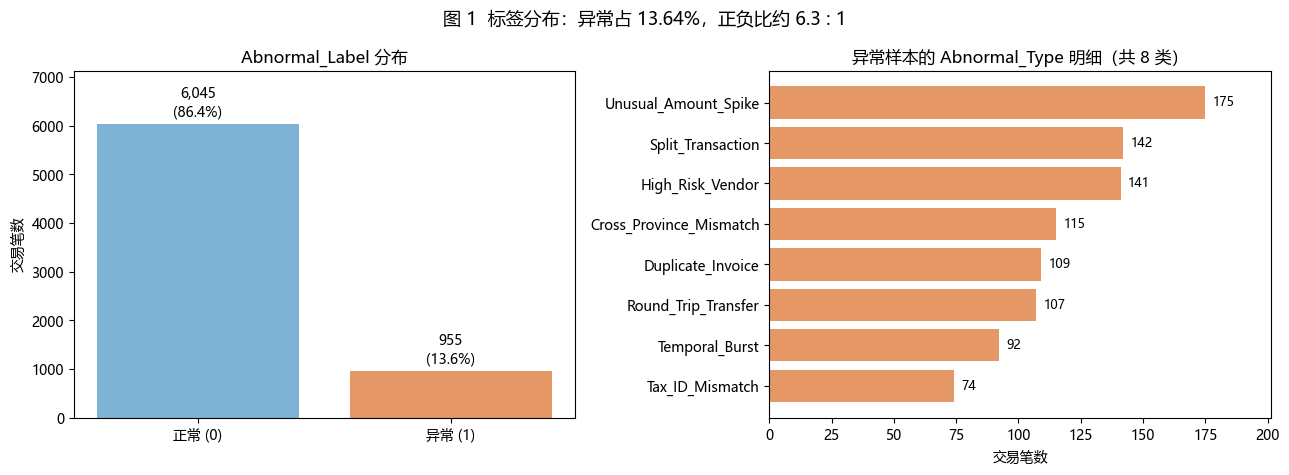

已保存: outputs/figures/01_label_distribution.png


In [7]:
# 画两张图：左边目标变量分布，右边异常类型明细
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

counts = [neg, pos]
bars = axes[0].bar(['正常 (0)', '异常 (1)'], counts, color=['#7FB3D5', '#E59866'])
for b, v in zip(bars, counts):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 80, f'{v:,}\n({v / len(df):.1%})',
                 ha='center', va='bottom', fontsize=10)
axes[0].set_title('Abnormal_Label 分布')
axes[0].set_ylabel('交易笔数')
axes[0].set_ylim(0, max(counts) * 1.18)

type_only = type_counts.drop('Normal').sort_values()
bars2 = axes[1].barh(type_only.index, type_only.values, color='#E59866')
for b, v in zip(bars2, type_only.values):
    axes[1].text(v + 3, b.get_y() + b.get_height() / 2, f'{v}', va='center', fontsize=9)
axes[1].set_title('异常样本的 Abnormal_Type 明细（共 8 类）')
axes[1].set_xlabel('交易笔数')
axes[1].set_xlim(0, type_only.max() * 1.15)

fig.suptitle('图 1  标签分布：异常占 13.64%，正负比约 6.3 : 1', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / '01_label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('已保存: outputs/figures/01_label_distribution.png')

**本数据集的结果：**

- 异常 **955 条，占 13.64%**；正常 6,045 条。正负比约 **6.3 : 1**，属于中度不平衡，但还不至于必须做过采样。
- 评估时应重点看 **Top-K 召回**（文档 3.3 的做法），而不是只看准确率——全部猜"正常"也有 **86.4%** 的准确率，这个数字没有意义。
- `Abnormal_Type == 'Normal'` 与 `Abnormal_Label == 0` **完全一致**；`Risk_Class == 0` 也与 `Abnormal_Label == 0` 完全一致。
- 因此 **`Abnormal_Type` 和 `Risk_Class` 是标签的派生列，建模时必须剔除**，否则模型等于直接看到了答案（标签泄漏）。
- `Risk_Class == 2` 只在异常样本中出现（80 条），可以理解为"高风险异常"，但它同样不能作为特征。

## 6. 数值字段：分布与偏态

Isolation Forest 通过随机切分来隔离样本。如果某个字段有极端大值（长尾），切分点会被少数极端值主导，异常分数就会失真。所以先看**偏度（skew）**：

| 偏度 | 含义 |
|---|---|
| \|skew\| < 0.5 | 接近对称 |
| 0.5 – 1 | 轻度偏斜 |
| > 1 | 明显右偏，考虑 `log1p` |
| > 2 | 严重右偏，基本必须变换 |

金额类字段是审计数据的典型长尾，重点看 `Transaction_Amount_RMB`。

In [8]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

num_summary = df[num_cols].describe().T
num_summary['偏度 skew'] = df[num_cols].skew()
num_summary['缺失率_%'] = (df[num_cols].isna().mean() * 100).round(2)
num_summary = num_summary.round(3)

print(f'数值字段共 {len(num_cols)} 个')
print('\n=== 数值字段统计描述 ===')
display(num_summary)

# 单独列出严重右偏的字段
skewed = num_summary[num_summary['偏度 skew'] > 2].sort_values('偏度 skew', ascending=False)
print('=== 严重右偏（skew > 2）的字段 ===')
display(skewed[['mean', '50%', 'max', '偏度 skew']])

num_summary.to_csv(OUT_DIR / 'numeric_summary.csv', encoding='utf-8-sig')
print('已保存: outputs/numeric_summary.csv')

数值字段共 36 个

=== 数值字段统计描述 ===


,count,mean,std,min,25%,50%,75%,max,偏度 skew,缺失率_%
Fiscal_Year,7000.0,2024.010,0.815,2023.000,2023.000,2024.000,2025.000,2025.000,-0.019,0.0
Fiscal_Quarter,7000.0,2.515,1.115,1.000,2.000,3.000,4.000,4.000,-0.024,0.0
Month,7000.0,6.538,3.447,1.000,4.000,7.000,10.000,12.000,-0.018,0.0
Hour,7000.0,11.362,6.917,0.000,5.000,11.000,17.000,23.000,0.024,0.0
Weekend_Flag,7000.0,0.285,0.451,0.000,0.000,0.000,1.000,1.000,0.955,0.0
Night_Transaction_Flag,7000.0,0.303,0.460,0.000,0.000,0.000,1.000,1.000,0.857,0.0
Source_Node_Index,7000.0,755.653,434.190,0.000,376.000,760.500,1132.250,1499.000,-0.005,0.0
Destination_Node_Index,7000.0,744.716,436.403,0.000,363.000,750.000,1118.000,1499.000,-0.003,0.0
Source_Account_Age_Days,7000.0,2187.339,1162.115,92.000,1185.000,2221.000,3170.000,4199.000,-0.040,0.0
Destination_Account_Age_Days,7000.0,2187.087,1169.096,92.000,1158.000,2224.000,3227.000,4199.000,-0.044,0.0


=== 严重右偏（skew > 2）的字段 ===


,mean,50%,max,偏度 skew
Amount_Threshold_Ratio,0.537,0.212,63.637,16.101
Transaction_to_Avg_Ratio,2.089,1.017,164.789,12.481
Transaction_Amount_RMB,50123.535,23063.125,3181864.090,10.700
Related_Party_Flag,0.016,0.000,1.000,7.645
Common_Counterparty_Count,6.677,6.000,77.000,7.190
Edge_Transaction_Count_30D,9.585,8.000,95.000,5.422
Duplicate_Invoice_Flag,0.047,0.000,1.000,4.297
Historical_Avg_Amount_RMB,28969.027,21778.990,565344.500,3.693
Risk_Class,0.148,0.000,2.000,2.563
Same_Bank_Flag,0.114,0.000,1.000,2.423


已保存: outputs/numeric_summary.csv


=== 金额字段关键数字 ===
  最小值   : 891
  中位数   : 23,063
  均值     : 50,124
  最大值   : 3,181,864
  最大 / 中位数: 138.0 倍
  偏度: 原始 10.70 -> log1p 后 0.52


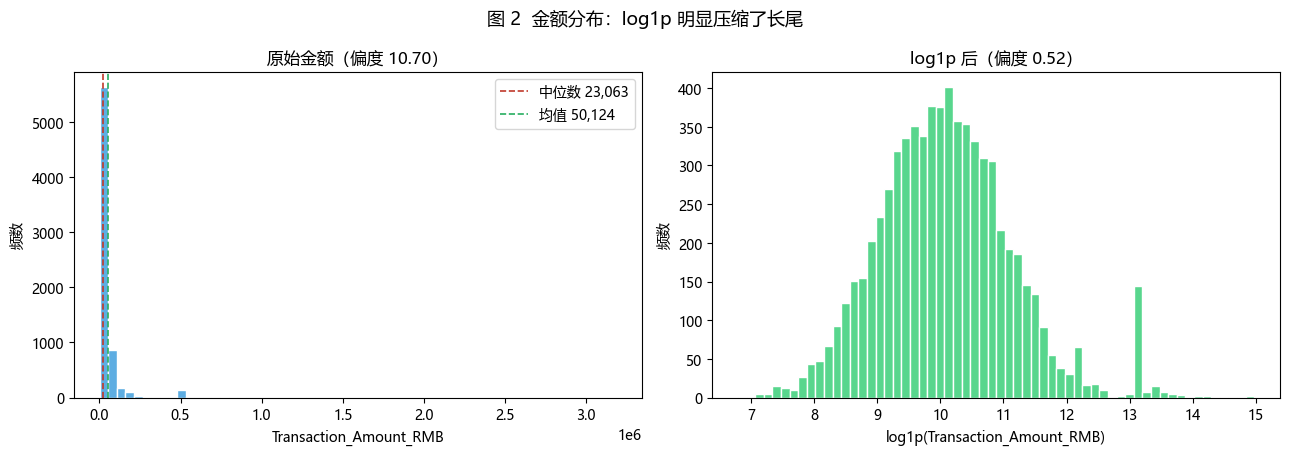

已保存: outputs/figures/02_amount_skew.png


In [9]:
# 金额字段：原始分布 vs log1p 后分布
amount = df['Transaction_Amount_RMB']
log_amount = np.log1p(amount)

print('=== 金额字段关键数字 ===')
print(f'  最小值   : {amount.min():,.0f}')
print(f'  中位数   : {amount.median():,.0f}')
print(f'  均值     : {amount.mean():,.0f}')
print(f'  最大值   : {amount.max():,.0f}')
print(f'  最大 / 中位数: {amount.max() / amount.median():.1f} 倍')
print(f'  偏度: 原始 {amount.skew():.2f} -> log1p 后 {log_amount.skew():.2f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].hist(amount, bins=60, color='#5DADE2', edgecolor='white')
axes[0].axvline(amount.median(), color='#C0392B', linestyle='--', linewidth=1.2,
                label=f'中位数 {amount.median():,.0f}')
axes[0].axvline(amount.mean(), color='#27AE60', linestyle='--', linewidth=1.2,
                label=f'均值 {amount.mean():,.0f}')
axes[0].set_title(f'原始金额（偏度 {amount.skew():.2f}）')
axes[0].set_xlabel('Transaction_Amount_RMB')
axes[0].set_ylabel('频数')
axes[0].legend()

axes[1].hist(log_amount, bins=60, color='#58D68D', edgecolor='white')
axes[1].set_title(f'log1p 后（偏度 {log_amount.skew():.2f}）')
axes[1].set_xlabel('log1p(Transaction_Amount_RMB)')
axes[1].set_ylabel('频数')

fig.suptitle('图 2  金额分布：log1p 明显压缩了长尾', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / '02_amount_skew.png', dpi=150, bbox_inches='tight')
plt.show()
print('已保存: outputs/figures/02_amount_skew.png')

**本数据集的结果：**

- `Transaction_Amount_RMB`：中位数约 **2.3 万**，最大 **318 万**，最大约是中位数的 **138 倍**，原始分布严重右偏。
- `Transaction_to_Avg_Ratio`（最大 164.8）、`Amount_Threshold_Ratio`（最大 63.6）同样是长尾。
- `log1p` 后偏度大幅下降，分布明显更对称 → 文档 2.3 对金额/比率类字段做 `log1p` 是合理的。
- `log1p` 只能用于**非负**字段；本数据金额全部 > 0，安全。
- 注意：`Historical_Avg_Amount_RMB`、`Approval_Threshold_RMB` 也偏态，但保留原始尺度便于解释；是否变换在清洗阶段统一决定。

## 7. 质量初检：清洗前的排雷

文档 2.4 要求检查重复交易 ID、金额 ≤ 0、时间戳异常，并记录删除条数与原因。这里先做一遍**只检查、不修改**的预检，把问题数量记下来，作为清洗前后的对照基线。

In [10]:
checks = []


def add_check(name, passed, detail):
    checks.append({
        '检查项': name,
        '结果': '通过' if passed else '发现问题',
        '详情': detail,
    })


# 1) 交易 ID 是否重复
dup_id = int(df['Transaction_ID'].duplicated().sum())
add_check('交易 ID 唯一', dup_id == 0, f'重复 {dup_id} 条')

# 2) 是否存在整行重复
dup_rows = int(df.duplicated().sum())
add_check('无整行重复', dup_rows == 0, f'重复行 {dup_rows} 条')

# 3) 金额是否为正
nonpos = int((df['Transaction_Amount_RMB'] <= 0).sum())
add_check('金额全部 > 0', nonpos == 0, f'金额 <= 0 共 {nonpos} 条')

# 4) 金额是否为空
amt_null = int(df['Transaction_Amount_RMB'].isna().sum())
add_check('金额无缺失', amt_null == 0, f'空值 {amt_null} 条')

# 5) 时间戳能否解析
dt = pd.to_datetime(df['Transaction_DateTime'], errors='coerce')
bad_dt = int(dt.isna().sum())
add_check('时间戳可解析', bad_dt == 0, f'无法解析 {bad_dt} 条')

# 6) 时间范围是否落在合理区间
in_range = bool(((dt >= '2023-01-01') & (dt <= '2025-12-31')).all())
add_check('时间范围合理', in_range,
          f'{dt.min().strftime("%Y-%m-%d")} ~ {dt.max().strftime("%Y-%m-%d")}')

# 7) 标签是否只有 0/1
label_ok = set(df['Abnormal_Label'].unique()) <= {0, 1}
add_check('标签只含 0/1', label_ok, f'实际取值 {sorted(df["Abnormal_Label"].unique())}')

quality_df = pd.DataFrame(checks)
print('=== 清洗前质量预检 ===')
display(quality_df)

quality_df.to_csv(OUT_DIR / 'quality_check_before_clean.csv', index=False, encoding='utf-8-sig')
print('已保存: outputs/quality_check_before_clean.csv')

=== 清洗前质量预检 ===


,检查项,结果,详情
0,交易 ID 唯一,通过,重复 0 条
1,无整行重复,通过,重复行 0 条
2,金额全部 > 0,通过,金额 <= 0 共 0 条
3,金额无缺失,通过,空值 0 条
4,时间戳可解析,通过,无法解析 0 条
5,时间范围合理,通过,2023-01-01 ~ 2025-12-30
6,标签只含 0/1,通过,"实际取值 [np.int64(0), np.int64(1)]"


已保存: outputs/quality_check_before_clean.csv


**本数据集的结果：全部通过。**

- 无重复交易 ID、无整行重复、金额全部 > 0、时间戳全部可解析且落在 2023-01-01 至 2025-12-30。
- 结论：清洗阶段**不需要删除任何行**，清洗后行数应保持 **7,000**（文档 2.5 的"行数基本不变"可以严格满足）。
- 预检表已留痕，清洗后再跑一次同样的检查，就能证明"清洗没有引入新问题"。

## 8. 派生字段与标签泄漏排查（很重要）

这一步文档里没有写，但对机器学习项目很关键：

1. **派生字段**：有些列是由其他列算出来的（比如比率 = 金额 / 均值）。它们本身没有错，但和"原材料"高度共线，建模时要避免重复表达同一信息。
2. **标签泄漏**：如果某个特征是由标签直接算出来的，模型在训练集上会表现极好，上线后却完全失效。相关系数接近 ±1 的字段要特别警惕。

下面先看所有数值字段与 `Abnormal_Label` 的相关系数，再验证两个比率字段是否由金额字段派生。

In [11]:
# 所有数值字段与目标变量的皮尔逊相关系数
corr_with_label = df[num_cols].corr()['Abnormal_Label'].drop('Abnormal_Label')
corr_with_label = corr_with_label.reindex(corr_with_label.abs().sort_values(ascending=False).index)

corr_df = corr_with_label.to_frame('与标签的相关系数').round(4)
print('=== 与 Abnormal_Label 相关性最强的 15 个数值字段 ===')
display(corr_df.head(15))

print('=== |相关系数| > 0.5 的字段（重点警惕） ===')
display(corr_df[corr_df['与标签的相关系数'].abs() > 0.5])

corr_df.to_csv(OUT_DIR / 'correlation_with_label.csv', encoding='utf-8-sig')
print('已保存: outputs/correlation_with_label.csv')

=== 与 Abnormal_Label 相关性最强的 15 个数值字段 ===


,与标签的相关系数
Risk_Class,0.9642
Audit_Rule_Violation_Count,0.5995
Relational_Anomaly_Score,0.4548
Invoice_Match_Score,-0.4238
Edge_Transaction_Count_30D,0.4140
Transaction_Amount_RMB,0.3610
Vendor_Risk_Score,0.3578
Transaction_to_Avg_Ratio,0.3377
Related_Party_Flag,0.3073
Amount_Threshold_Ratio,0.2786


=== |相关系数| > 0.5 的字段（重点警惕） ===


,与标签的相关系数
Risk_Class,0.9642
Audit_Rule_Violation_Count,0.5995


已保存: outputs/correlation_with_label.csv


In [12]:
# 验证两个比率字段是不是"金额 / 分母"算出来的
ratio_recalc = df['Transaction_Amount_RMB'] / df['Historical_Avg_Amount_RMB']
threshold_recalc = df['Transaction_Amount_RMB'] / df['Approval_Threshold_RMB']

ratio_diff = (df['Transaction_to_Avg_Ratio'] - ratio_recalc).abs().max()
threshold_diff = (df['Amount_Threshold_Ratio'] - threshold_recalc).abs().max()

print('=== 派生字段验证 ===')
print(f'Transaction_to_Avg_Ratio  = 金额 / 历史均值 ? 最大绝对误差 {ratio_diff:.6f}')
print(f'Amount_Threshold_Ratio    = 金额 / 审批阈值 ? 最大绝对误差 {threshold_diff:.6f}')
print('（最大误差仅为 CSV 保存时的四舍五入，可视为完全相等）')

=== 派生字段验证 ===
Transaction_to_Avg_Ratio  = 金额 / 历史均值 ? 最大绝对误差 0.000050
Amount_Threshold_Ratio    = 金额 / 审批阈值 ? 最大绝对误差 0.000050
（最大误差仅为 CSV 保存时的四舍五入，可视为完全相等）


**本数据集的结果与处理建议：**

- `Risk_Class` 与标签相关系数 **0.96** → 它是标签派生列，**必须剔除**（与第 5 节结论一致）。
- `Audit_Rule_Violation_Count`（0.60）、`Relational_Anomaly_Score`（0.45）、`Invoice_Match_Score`（−0.42）等与标签相关性较高，但它们是业务上**在打标签之前就能拿到的规则/评分**，可以作为特征；报告中要说明"规则分数参与了模型"，避免被问到时说不清。
- `Transaction_to_Avg_Ratio` 与"金额 / 历史均值"完全一致；`Amount_Threshold_Ratio` 与"金额 / 审批阈值"一致（误差仅来自四舍五入）→ 它们是派生字段。
- 处理建议：比率字段保留（业务含义强）；是否同时保留原始金额，取决于后续模型表现——树模型对共线不敏感，但解释性会变差，报告中说明即可。
- 相关系数只能看**线性**关系。Isolation Forest 是非线性的，相关低不代表没用；这里只用来排查"高得离谱"的泄漏。

## 9. 探查小结

| 问题 | 结论 | 对下一步的影响 |
|---|---|---|
| 规模 | 7,000 × 59，与文档一致 | 无需抽样 |
| 缺失 | 0 缺失 | 跳过 2.1 填充，报告中说明计划修正 |
| 常量列 | `Currency` 只有 CNY | 清洗时剔除 |
| 编码 | 低基数类别 2–25 个取值；ID 类高基数 | 只对低基数业务类别 One-Hot |
| 标签 | 异常 955 条（13.64%），6.3 : 1 | 用 Top-K 召回评估，别只看准确率 |
| 泄漏 | `Abnormal_Type`、`Risk_Class` 由标签派生 | 建模特征集中剔除 |
| 偏态 | 金额类严重右偏 | 清洗时 `log1p` + 标准化 |
| 质量 | 无重复、无负金额、时间戳正常 | 清洗不删行，行数保持 7,000 |
| 派生 | 两个比率字段由金额算出 | 保留比率，注意共线 |

**下一步（文档 2.1—2.5 清洗）：** 建立 `02_clean.ipynb`，按上述结论执行：

1. 从建模特征中剔除常量列 `Currency` 与标签派生列 `Abnormal_Type`、`Risk_Class`（`Abnormal_Type` 仍保留在数据里，仅用于后续案例分析）；
2. 只对低基数业务类别做 One-Hot（ID/名称类不编码）；
3. 金额与比率类字段做 `log1p`，数值字段做 z-score 标准化；
4. 再跑一遍质量检查，与本节预检结果对照；
5. 导出 `audit_clean.csv` 并记录维度变化。

In [13]:
# ============================================================
# 生成总的"数据概览表"和文字版小结，作为本阶段的留痕
# ============================================================
overview = pd.DataFrame({
    '字段分组': [meta[c][0] for c in df.columns],
    '字段名': list(df.columns),
    '字段含义': [meta[c][1] for c in df.columns],
    'dtype': df.dtypes.astype(str).values,
    '缺失数': df.isna().sum().values,
    '缺失率_%': (df.isna().mean() * 100).round(2).values,
    '唯一值数': df.nunique().values,
    '示例值': [df[c].iloc[0] for c in df.columns],
})
overview.to_csv(OUT_DIR / 'data_overview.csv', index=False, encoding='utf-8-sig')

amount = df['Transaction_Amount_RMB']
summary = f'''智慧审计数据集 · 初步探查小结
生成时间: {datetime.now():%Y-%m-%d %H:%M:%S}
数据文件: {DATA_PATH.resolve()}

规模: {df.shape[0]} 行 x {df.shape[1]} 列
缺失单元格: {int(df.isna().sum().sum())}
常量列: {', '.join(constant_cols) if constant_cols else '无'}

标签:
  正常 (0): {neg} 条
  异常 (1): {pos} 条 ({pos / len(df):.2%})
  正负比: {neg / pos:.2f} : 1
  异常类型数: {df.loc[df['Abnormal_Label'] == 1, 'Abnormal_Type'].nunique()}

金额:
  中位数 {amount.median():,.0f} | 均值 {amount.mean():,.0f} | 最大 {amount.max():,.0f}
  最大/中位数 = {amount.max() / amount.median():.1f} 倍
  偏度 原始 {amount.skew():.2f} -> log1p 后 {np.log1p(amount).skew():.2f}

质量预检: 全部通过（重复 ID {dup_id} / 重复行 {dup_rows} / 非正金额 {nonpos} / 无法解析时间 {bad_dt}）

泄漏字段: Abnormal_Type, Risk_Class（均为标签派生，建模剔除）
派生字段: Transaction_to_Avg_Ratio, Amount_Threshold_Ratio

关键图表:
  outputs/figures/01_label_distribution.png
  outputs/figures/02_amount_skew.png
'''
(OUT_DIR / 'explore_summary.txt').write_text(summary, encoding='utf-8')

print(summary)
print('=' * 60)
print('本次探查生成的留痕文件：')
for p in sorted(OUT_DIR.rglob('*')):
    if p.is_file():
        print(f'  {p.as_posix():50s} {p.stat().st_size / 1024:8.1f} KB')

智慧审计数据集 · 初步探查小结
生成时间: 2026-10-18 22:47:19
数据文件: D:\ProjectFiles\VscodeProject\audit_ml_project\data\audit_raw.csv

规模: 7000 行 x 59 列
缺失单元格: 0
常量列: Currency

标签:
  正常 (0): 6045 条
  异常 (1): 955 条 (13.64%)
  正负比: 6.33 : 1
  异常类型数: 8

金额:
  中位数 23,063 | 均值 50,124 | 最大 3,181,864
  最大/中位数 = 138.0 倍
  偏度 原始 10.70 -> log1p 后 0.52

质量预检: 全部通过（重复 ID 0 / 重复行 0 / 非正金额 0 / 无法解析时间 0）

泄漏字段: Abnormal_Type, Risk_Class（均为标签派生，建模剔除）
派生字段: Transaction_to_Avg_Ratio, Amount_Threshold_Ratio

关键图表:
  outputs/figures/01_label_distribution.png
  outputs/figures/02_amount_skew.png

本次探查生成的留痕文件：
  ../outputs/categorical_cardinality.csv                  1.7 KB
  ../outputs/correlation_with_label.csv                   1.0 KB
  ../outputs/data_overview.csv                            5.0 KB
  ../outputs/dtype_missing_summary.csv                    2.4 KB
  ../outputs/explore_summary.txt                          0.8 KB
  ../outputs/field_dictionary.csv                         4.4 KB
  ../outputs/figures/01_label_dis

**留痕文件清单（都已生成）：**

| 文件 | 内容 |
|---|---|
| `outputs/data_overview.csv` | 59 列的完整概览：分组、含义、类型、缺失、唯一值、示例 |
| `outputs/field_dictionary.csv` | 字段字典（分组 + 中文含义） |
| `outputs/dtype_missing_summary.csv` | 每列类型、缺失率、唯一值 |
| `outputs/categorical_cardinality.csv` | 类别字段基数与编码建议 |
| `outputs/numeric_summary.csv` | 数值字段描述统计 + 偏度 |
| `outputs/quality_check_before_clean.csv` | 清洗前质量预检 |
| `outputs/correlation_with_label.csv` | 各数值字段与标签的相关系数 |
| `outputs/explore_summary.txt` | 文字版小结（含运行时间） |
| `outputs/figures/01_label_distribution.png` | 标签分布图 |
| `outputs/figures/02_amount_skew.png` | 金额原始 vs log1p 对比图 |

下一节进入 **阶段二：数据清洗（02_clean.ipynb）**。